# 06. Implicação de receita

Fase 6, revista depois da auditoria externa. Responde uma pergunta só: o
que acontece com a arrecadação de mercado de **um** setor quando o preço da
Inteira **desse** setor sobe em relação aos outros setores do mesmo jogo,
com a incerteza propagada. Sem preço ótimo, sem recomendação e sem valores
em reais.

**O que não se pode fazer com este número.** Ele não pode ser somado sobre
os setores do jogo nem multiplicado por uma receita agregada. Se todos os
setores do jogo sobem 10%, nenhum subiu em relação aos outros, e o efeito
fixo de partida absorve esse movimento: a base não identifica o efeito de
uma alta geral.

**Por que o coeficiente direto, e não 1 + beta.** O preço do modelo é o da
Inteira, mas a quantidade soma Inteira e Meia. Receita = preço x
quantidade só valeria com o mesmo preço nos dois lados. Por isso o
efeito sobre a receita é estimado diretamente, com log(arrecadação de
mercado do setor) como dependente, na mesma especificação E2, com erro
agrupado por jogo e setor.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from linearmodels import PanelOLS

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = RAIZ / "figuras" / "06_receita"
FIG.mkdir(parents=True, exist_ok=True)

base = pd.read_csv(RAIZ / "data" / "03_processed" / "boletins.csv")
ipca = pd.read_csv(RAIZ / "referencias" / "ipca.csv").set_index("ano").ipca_variacao_anual_pct
ULTIMA = base.ano.max()
fator = {t: float(np.prod([1 + ipca[y] / 100 for y in range(t, ULTIMA)])) for t in sorted(base.ano.unique())}

# Mesma construção da Fase 5 (notebooks/05_modelo.ipynb).
merc = base[base.regime == "mercado"]
chave = ["ano", "jogo", "mandante", "setor"]
precos = merc[~merc.preco_regulado].groupby(chave).preco.agg(["nunique", "first"])
agregado = merc.groupby(chave).agg(q=("vendidos", "sum"), arrecadacao=("arrecadacao", "sum"))
d = (precos[precos["nunique"] == 1]["first"].rename("preco").to_frame()
     .join(agregado, how="inner").reset_index())
d["id_setor"] = d.mandante + " | " + d.setor
d["id_jogo"] = d.ano.astype(str) + "_" + d.jogo.astype(str)
d["lq"] = np.log(d.q)
d["lp"] = np.log(d.preco)
d["la"] = np.log(d.arrecadacao)
d["lpm"] = np.log(d.arrecadacao / d.q)
d["preco_real"] = d.preco * d.ano.map(fator)
print(f"Unidades: {len(d):,}  jogos: {d.id_jogo.nunique()}  setores: {d.id_setor.nunique()}")

Unidades: 2,212  jogos: 387  setores: 337


## Coeficientes, com erro agrupado por jogo e setor

In [2]:
def estimar(y):
    df = d.copy()
    df["t"] = pd.factorize(df.id_jogo)[0]
    p = df.set_index(["id_setor", "t"])
    r = PanelOLS(p[y], p[["lp"]], entity_effects=True, time_effects=True).fit(
        cov_type="clustered", cluster_time=True, cluster_entity=True)
    ic = r.conf_int().loc["lp"]
    return {"beta": r.params.lp, "ic95_inf": ic.lower, "ic95_sup": ic.upper, "n_obs": int(r.nobs)}


coef = pd.DataFrame({
    "log(q): elasticidade da quantidade": estimar("lq"),
    "log(preço médio realizado): repasse da Inteira": estimar("lpm"),
    "log(arrecadação do setor): efeito sobre a receita": estimar("la"),
}).T
print(coef.round(3).to_string())
print(f"Identidade: {coef.beta.iloc[0]:.3f} + {coef.beta.iloc[1]:.3f} = "
      f"{coef.beta.iloc[0] + coef.beta.iloc[1]:.3f} (arrecadação: {coef.beta.iloc[2]:.3f})")

                                                    beta  ic95_inf  ic95_sup   n_obs
log(q): elasticidade da quantidade                -0.468    -0.975     0.039  2212.0
log(preço médio realizado): repasse da Inteira     0.916     0.851     0.981  2212.0
log(arrecadação do setor): efeito sobre a receita  0.448    -0.073     0.968  2212.0
Identidade: -0.468 + 0.916 = 0.448 (arrecadação: 0.448)


O repasse da Inteira para o preço médio realizado do setor é menor que 1:
parte do público paga Meia, que acompanha a Inteira, mas a composição
também muda. Por isso 1 + beta não serve como multiplicador da receita.

## Variação da arrecadação de um setor com preço relativo alterado

Variação percentual da arrecadação de mercado do setor, (1 + Δ)^b - 1, com
b o coeficiente de log(arrecadação), no ponto e nos dois extremos do IC
95%. Só em percentual. Os valores não podem ser somados sobre os setores
do jogo nem aplicados a uma receita agregada.

In [3]:
b = coef.loc["log(arrecadação do setor): efeito sobre a receita"]
variacoes = [-0.20, -0.10, 0.10, 0.20]
tabela = pd.DataFrame([{
    "variacao_preco_relativo": f"{dp:+.0%}",
    "pct_limite_inferior_ic": 100 * ((1 + dp) ** b.ic95_inf - 1),
    "pct_pontual": 100 * ((1 + dp) ** b.beta - 1),
    "pct_limite_superior_ic": 100 * ((1 + dp) ** b.ic95_sup - 1),
} for dp in variacoes])
print(tabela.round(2).to_string(index=False))
tabela.round(4).to_csv(FIG / "variacao_receita.csv", index=False)
contem_zero = b.ic95_inf < 0 < b.ic95_sup
print(f"O IC 95% do coeficiente contém zero: {contem_zero}")

variacao_preco_relativo  pct_limite_inferior_ic  pct_pontual  pct_limite_superior_ic
                   -20%                    1.63        -9.51                  -19.43
                   -10%                    0.77        -4.61                   -9.70
                   +10%                   -0.69         4.36                    9.67
                   +20%                   -1.31         8.51                   19.30
O IC 95% do coeficiente contém zero: True


## Faixa de preço observada

A conta não deve ser lida fora da faixa de preço já praticada. Faixa de
cada setor: mínimo e máximo do preço real (R$ 2026) do setor na base.
Abaixo, quantos setor-jogos sairiam da faixa do próprio setor com cada
variação.

In [4]:
faixa = d.groupby("id_setor").preco_real.agg(minimo="min", maximo="max", jogos="size")
faixa["razao_max_min"] = faixa.maximo / faixa.minimo
d = d.join(faixa[["minimo", "maximo"]], on="id_setor")
print(f"Setores: {len(faixa)}; com faixa nula (um só preço real): {(faixa.minimo == faixa.maximo).sum()}")
print("Razão entre preço máximo e mínimo do setor:")
print(faixa.razao_max_min.describe(percentiles=[0.25, 0.5, 0.75, 0.9]).round(3).to_string())
print()
for dp in variacoes:
    novo = d.preco_real * (1 + dp)
    fora = (novo > d.maximo * (1 + 1e-9)) | (novo < d.minimo * (1 - 1e-9))
    print(f"{dp:+.0%}: {fora.sum():,} de {len(d):,} setor-jogos saem da faixa do setor ({fora.mean():.1%})")
faixa.round(2).sort_values("razao_max_min").to_csv(FIG / "faixa_preco_por_setor.csv")

Setores: 337; com faixa nula (um só preço real): 142
Razão entre preço máximo e mínimo do setor:
count    337.000
mean       1.920
std        1.453
min        1.000
25%        1.000
50%        1.400
75%        2.390
90%        3.656
max       12.500

-20%: 1,135 de 2,212 setor-jogos saem da faixa do setor (51.3%)
-10%: 947 de 2,212 setor-jogos saem da faixa do setor (42.8%)
+10%: 582 de 2,212 setor-jogos saem da faixa do setor (26.3%)
+20%: 663 de 2,212 setor-jogos saem da faixa do setor (30.0%)


## Concentração das observações

Quanto da base utilizável vem dos quatro maiores mandantes.

In [5]:
grandes = ["São Paulo", "Palmeiras", "Santos", "Corinthians"]
eh_grande = d.mandante.isin(grandes)
print(f"Setor-jogos dos quatro grandes: {eh_grande.sum():,} de {len(d):,} ({eh_grande.mean():.1%})")
print(f"Ingressos de mercado (q) dos quatro grandes: {d.q[eh_grande].sum() / d.q.sum():.1%}")
print(f"Jogos com os quatro grandes como mandante: "
      f"{d[eh_grande].id_jogo.nunique()} de {d.id_jogo.nunique()}")

Setor-jogos dos quatro grandes: 1,118 de 2,212 (50.5%)
Ingressos de mercado (q) dos quatro grandes: 58.0%
Jogos com os quatro grandes como mandante: 110 de 387


## Por que não há preço ótimo aqui

Com coeficiente de arrecadação positivo e constante, a receita do setor
cresce sem limite com o preço no modelo. Isso é consequência da forma
funcional, não do mundo. O IC 95% do coeficiente contém zero, então nem o
sinal do efeito sobre a receita está estabelecido. Fora da faixa
observada o efeito não é conhecido.

## Gráfico

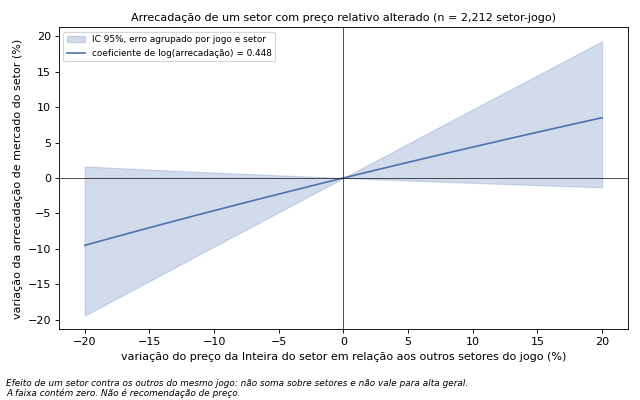

In [6]:
grade = np.linspace(-0.20, 0.20, 81)
fig, ax = plt.subplots(figsize=(8, 5))
ax.fill_between(100 * grade, 100 * ((1 + grade) ** b.ic95_inf - 1),
                100 * ((1 + grade) ** b.ic95_sup - 1), color="#4C72B0", alpha=0.25,
                label="IC 95%, erro agrupado por jogo e setor")
ax.plot(100 * grade, 100 * ((1 + grade) ** b.beta - 1), color="#4C72B0",
        label=f"coeficiente de log(arrecadação) = {b.beta:.3f}")
ax.axhline(0, color="black", lw=0.6)
ax.axvline(0, color="black", lw=0.6)
ax.set_xlabel("variação do preço da Inteira do setor em relação aos outros setores do jogo (%)")
ax.set_ylabel("variação da arrecadação de mercado do setor (%)")
ax.set_title(f"Arrecadação de um setor com preço relativo alterado (n = {int(b.n_obs):,} setor-jogo)",
             fontsize=10)
ax.legend(fontsize=8)
fig.text(0.01, 0.035, "Efeito de um setor contra os outros do mesmo jogo: não soma sobre setores e não vale para alta geral.",
         fontsize=8, style="italic")
fig.text(0.01, 0.01, "A faixa contém zero. Não é recomendação de preço.", fontsize=8, style="italic")
fig.tight_layout(rect=(0, 0.06, 1, 1))
fig.savefig(FIG / "variacao_receita.png", dpi=150)
plt.show()

## Por que isso não é recomendação de preço

A conta acima responde só a uma pergunta estreita: quanto a arrecadação de
mercado de um setor variaria se o clube mudasse o preço da Inteira desse
setor em relação aos outros do mesmo jogo, dentro da faixa já praticada.
Ela ignora:

- **Consumo dentro do estádio.** Alimentação, bebida e produtos dependem do
  público presente, não do preço do ingresso. Menos público é menos
  consumo.
- **Conversão de sócio.** Ingresso avulso caro é também argumento de venda
  do programa de sócio-torcedor. A receita de sócio não está nesta conta.
- **Formação de torcedor no longo prazo.** Preço que afasta o público
  jovem ou de menor renda hoje reduz a base de torcedores de amanhã.
- **Ambiente.** Estádio cheio tem valor esportivo, de transmissão e de
  patrocínio que a bilheteria não mede.
- **Capacidade.** Sem a capacidade do setor, não se sabe quem esgotou. A
  censura puxa a elasticidade para zero e o filtro por ocupação aparente é
  proxy, não correção.
- **O clube pode estar escolhendo isso de propósito.** Preço abaixo do que
  maximizaria a bilheteria pode ser decisão consciente, pelos motivos
  acima.